# 03 — Universe master feature table

Build one **pooled labeled table** from all available symbols for a selected interval, plus a separate **latest-bar inference table**. This notebook does not train a predictive model.

**Leakage rules:** features are computed independently for each ticker; targets never cross ticker boundaries; quantile boundaries, K-means, and preprocessing are fitted on the earlier chronological training period only. The final bar per ticker has no known next-bar outcome and is reserved for future inference.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from stock_ml_dynamic.db import engine
from stock_ml_dynamic.master_table import (fetch_universe_prices, build_universe_features, assemble_master_table, model_ready, save_master_outputs, FEATURE_COLUMNS, NUMERIC_FEATURES, CATEGORICAL_FEATURES)


## 1. Settings

`SYMBOLS=None` means all stocks present for this interval (expected: 220). Start with `1d`; run separately for intraday/weekly/monthly intervals. `BARS_PER_SYMBOL` limits the most recent bars fetched per stock. Use `SELECTED_K=None` for the elbow heuristic, or an integer from 2 to 8.

In [2]:
INTERVAL = "1d"
BARS_PER_SYMBOL = 2000
SYMBOLS = None  # or ["AAPL", "MSFT"] for a quick trial
TRAIN_FRACTION = 0.80
Z_WINDOW = 30
SELECTED_K = None
SAVE_RESULTS = True


## 2. Read the universe from PostgreSQL

One read-only SQL query obtains up to `BARS_PER_SYMBOL` bars **per ticker**, not globally.

In [3]:
with engine().connect() as conn:
    prices = fetch_universe_prices(conn, interval=INTERVAL, bars_per_symbol=BARS_PER_SYMBOL, symbols=SYMBOLS)
print(f"Raw bars: {len(prices):,}; symbols: {prices.symbol.nunique()}; interval: {INTERVAL}")
display(prices.groupby("symbol").size().describe().to_frame("bars_per_symbol"))
display(prices.head())


Raw bars: 431,519; symbols: 220; interval: 1d


,bars_per_symbol
count,220.000000
mean,1961.450000
std,205.072639
min,31.000000
25%,2000.000000
50%,2000.000000
75%,2000.000000
max,2000.000000


,symbol,interval_code,bar_timestamp,open_price,high_price,low_price,close_price,adj_close_price,volume
0,AAPL,1d,2018-11-28 00:00:00+00:00,44.182499,45.322498,43.732498,45.235001,42.894093,184250000
1,AAPL,1d,2018-11-29 00:00:00+00:00,45.665001,45.700001,44.424999,44.887501,42.564564,167080000
2,AAPL,1d,2018-11-30 00:00:00+00:00,45.072498,45.082500,44.257500,44.645000,42.334625,158126000
3,AAPL,1d,2018-12-03 00:00:00+00:00,46.115002,46.235001,45.302502,46.205002,43.813896,163210000
4,AAPL,1d,2018-12-04 00:00:00+00:00,45.237499,45.597500,44.067501,44.172501,41.886570,165377200


## 3. Build causal features and next-bar outcomes

`direction` is still unknown here: it will be assigned using **training-only quantile boundaries**. `next_adj_close` and `next_return` are computed separately within each stock.

In [4]:
features = build_universe_features(prices, z_window=Z_WINDOW)
print("Feature rows:", len(features))
display(features[["symbol", "bar_timestamp"] + NUMERIC_FEATURES + ["next_adj_close", "next_return"]].tail(8))


Feature rows: 431519


,symbol,bar_timestamp,top_pct,body_pct,bottom_pct,gap,adj_z,slope,concavity,next_adj_close,next_return
431511,XOM,2026-11-03 00:00:00+00:00,0.741935,0.174191,0.083874,-0.339431,0.634522,0.475014,5.370011,169.270004,-0.046151
431512,XOM,2026-11-04 00:00:00+00:00,0.048477,0.691134,0.260388,-1.032260,-0.380796,-11.180009,-5.980012,165.300003,-0.023454
431513,XOM,2026-11-05 00:00:00+00:00,0.305979,0.675263,0.018758,0.247922,-0.906087,-1.860000,4.220002,165.869995,0.003448
431514,XOM,2026-11-06 00:00:00+00:00,0.280487,0.493901,0.225611,-0.123095,-0.862410,2.839988,4.539993,164.729996,-0.006873
431515,XOM,2026-11-09 00:00:00+00:00,0.302585,0.335788,0.361627,-0.624997,-1.053064,-1.994994,-1.709991,164.470001,-0.001578
431516,XOM,2026-11-10 00:00:00+00:00,0.101032,0.538144,0.360824,-1.059036,-1.108155,0.180007,0.880004,166.710007,0.013620
431517,XOM,2026-11-11 00:00:00+00:00,0.017464,0.685595,0.296941,0.138144,-0.850236,3.490006,2.500001,169.779999,0.018415
431518,XOM,2026-11-12 00:00:00+00:00,0.318435,0.427374,0.254191,0.672488,-0.476687,3.484985,0.829986,NaN,NaN


## 4. Fit training-only target bins, K-means candle types, and preprocessing

The same fitted transforms will later be used for every stock and for live predictions. The global chronological cutoff avoids fitting on future timestamps of other tickers.

Train cutoff: 2025-04-10 00:00:00+00:00
Selected K: 4
Quantile edges: [-0.52907387 -0.00517697  0.00670066  0.74593226]


,k,inertia
0,2,934765.700585
1,3,681720.791158
2,4,559765.759267
3,5,490741.258700
4,6,435004.305574
5,7,392913.858965
6,8,352626.469590


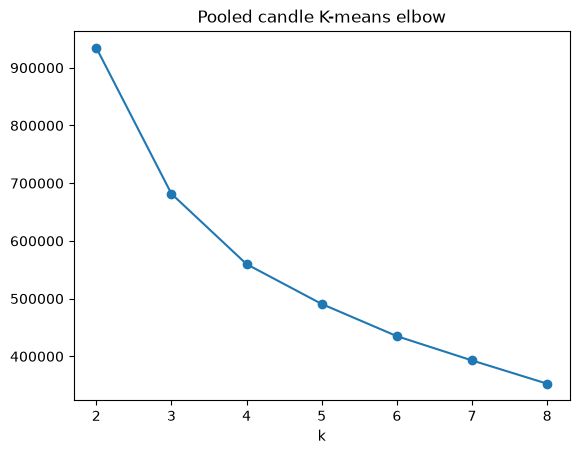

In [5]:
result = assemble_master_table(features, train_fraction=TRAIN_FRACTION, selected_k=SELECTED_K)
print("Train cutoff:", result.cutoff)
print("Selected K:", result.clusters.chosen_k_)
print("Quantile edges:", result.quantiles.edges_)
display(result.clusters.inertia_)
result.clusters.inertia_.plot(x="k", y="inertia", marker="o", title="Pooled candle K-means elbow", legend=False)
plt.show()


## 5. Inspect the labeled master table and latest-bar inference rows

There is one latest bar per ticker with **unknown direction and next adjusted close**. Those rows are intentionally absent from `master` but retained in `inference`.

In [6]:
master = result.master
inference = result.inference
cols = ["symbol", "interval_code", "bar_timestamp"] + FEATURE_COLUMNS + ["direction", "adj_close", "next_adj_close", "next_return"]
print(f"Master: {len(master):,} labeled rows across {master.symbol.nunique()} stocks")
print(f"Inference: {len(inference):,} latest rows across {inference.symbol.nunique()} stocks")
display(master[cols].head(10))
display(inference[cols].tail(10))
assert master.direction.notna().all()
assert inference.direction.isna().all()
assert inference.next_adj_close.isna().all()


Master: 431,299 labeled rows across 220 stocks
Inference: 220 latest rows across 220 stocks


,symbol,interval_code,bar_timestamp,top_pct,body_pct,bottom_pct,gap,adj_z,slope,concavity,candle_type,month_of_year,day_of_month,day_of_week,hour_of_day,direction,adj_close,next_adj_close,next_return
0,AAPL,1d,2018-11-28 00:00:00+00:00,0.055030,0.661951,0.283019,0.000000,NaN,NaN,NaN,3,11,27,1,19,2,42.894093,42.564564,-0.007682
1,AAPL,1d,2018-11-29 00:00:00+00:00,0.027451,0.609803,0.362746,0.270440,NaN,NaN,NaN,3,11,28,2,19,2,42.564564,42.334625,-0.005402
2,AAPL,1d,2018-11-30 00:00:00+00:00,0.012124,0.518179,0.469697,0.145095,NaN,-0.180144,0.099590,0,11,29,3,19,1,42.334625,43.813896,0.034942
3,AAPL,1d,2018-12-03 00:00:00+00:00,0.032171,0.096515,0.871315,1.781821,NaN,2.333876,1.709210,0,12,2,6,19,2,43.813896,41.886570,-0.043989
4,AAPL,1d,2018-12-04 00:00:00+00:00,0.235295,0.696078,0.068627,-1.037538,NaN,-3.630625,-3.406597,3,12,3,0,19,2,41.886570,41.419563,-0.011149
5,AAPL,1d,2018-12-06 00:00:00+00:00,0.013761,0.678900,0.307339,-0.805557,NaN,0.263152,1.460319,3,12,5,2,19,2,41.419563,39.942661,-0.035657
6,AAPL,1d,2018-12-07 00:00:00+00:00,0.161551,0.807754,0.030695,-0.282109,NaN,-1.981849,-1.009895,3,12,6,3,19,0,39.942661,40.205811,0.006588
7,AAPL,1d,2018-12-10 00:00:00+00:00,0.072483,0.680475,0.247042,-0.563813,NaN,1.133176,1.740052,3,12,9,6,19,2,40.205811,39.975864,-0.005719
8,AAPL,1d,2018-12-11 00:00:00+00:00,0.027137,0.632569,0.340294,0.304733,NaN,-0.476495,-0.493097,3,12,10,0,19,0,39.975864,40.087280,0.002787
9,AAPL,1d,2018-12-12 00:00:00+00:00,0.524141,0.448271,0.027588,0.369518,NaN,0.282097,0.341363,1,12,11,1,19,1,40.087280,40.525852,0.010940


,symbol,interval_code,bar_timestamp,top_pct,body_pct,bottom_pct,gap,adj_z,slope,concavity,candle_type,month_of_year,day_of_month,day_of_week,hour_of_day,direction,adj_close,next_adj_close,next_return
413518,VYLR,1d,2026-11-12 00:00:00+00:00,0.389176,0.012886,0.597938,-0.046630,-0.223456,0.155000,0.390001,0,11,11,2,19,<NA>,72.059998,NaN,NaN
415518,VZ,1d,2026-11-12 00:00:00+00:00,0.228919,0.493975,0.277107,0.473684,1.596014,-0.219997,-0.339996,3,11,11,2,19,<NA>,46.549999,NaN,NaN
417518,WEC,1d,2026-11-12 00:00:00+00:00,0.027777,0.694443,0.277780,0.457832,1.324154,-0.214997,-0.449997,3,11,11,2,19,<NA>,117.480003,NaN,NaN
419518,WELL,1d,2026-11-12 00:00:00+00:00,0.243138,0.701960,0.054902,0.321327,1.322078,-3.475021,-2.110015,3,11,11,2,19,<NA>,244.929993,NaN,NaN
421518,WFC,1d,2026-11-12 00:00:00+00:00,0.377361,0.481129,0.141511,0.643825,1.537907,-0.080002,-0.080002,1,11,11,2,19,<NA>,85.760002,NaN,NaN
423518,WM,1d,2026-11-12 00:00:00+00:00,0.245856,0.085635,0.668509,0.785237,1.385831,4.275018,0.910020,0,11,11,2,19,<NA>,244.110001,NaN,NaN
425518,WMB,1d,2026-11-12 00:00:00+00:00,0.573862,0.323864,0.102274,-0.030672,-0.541022,0.050007,-0.939995,1,11,11,2,19,<NA>,69.440002,NaN,NaN
427518,WMT,1d,2026-11-12 00:00:00+00:00,0.394496,0.279817,0.325687,0.504467,1.114966,0.720009,0.400009,1,11,11,2,19,<NA>,126.190002,NaN,NaN
429518,XEL,1d,2026-11-12 00:00:00+00:00,0.458823,0.094120,0.447056,0.403364,1.564862,0.110005,-0.579993,1,11,11,2,19,<NA>,81.500000,NaN,NaN
431518,XOM,1d,2026-11-12 00:00:00+00:00,0.318435,0.427374,0.254191,0.672488,-0.476687,3.484985,0.829986,1,11,11,2,19,<NA>,169.779999,NaN,NaN


## 6. Class distribution and missingness

Class IDs: **2 = down, 0 = no_change, 1 = up**. With pooled quantiles, global training classes are approximately balanced, but individual stocks can differ.

In [7]:
display(master.direction.value_counts(dropna=False).rename_axis("direction").to_frame("rows"))
display(master.groupby("symbol").size().describe().to_frame("labeled_rows_per_symbol"))
display(master[FEATURE_COLUMNS].isna().sum().to_frame("missing_feature_rows"))


,rows
direction,
1,144658
2,144134
0,142507


,labeled_rows_per_symbol
count,220.000000
mean,1960.450000
std,205.072639
min,30.000000
25%,1999.000000
50%,1999.000000
75%,1999.000000
max,1999.000000


,missing_feature_rows
top_pct,0
body_pct,0
bottom_pct,0
gap,0
adj_z,6600
slope,440
concavity,440
candle_type,0
month_of_year,0
day_of_month,0


## 7. Model-ready matrices

`X_master` is numerically standardized and categoricals are one-hot encoded using **training-only fitted preprocessing**. Use `train_rows` to select training data and `~train_rows` for chronological validation. **Do not refit** the scaler/encoder on test or inference data. For regression, `next_adj_close` is the next-bar target, while `adj_close` is the current observed price.

In [8]:
X_master, aligned_master = model_ready(result, "master")
X_latest, aligned_latest = model_ready(result, "inference")
y_class = aligned_master.direction.astype(int)
y_reg = aligned_master.next_adj_close.astype(float)
train_rows = aligned_master.next_bar_timestamp <= result.cutoff
print("X master:", X_master.shape, "X latest:", X_latest.shape)
print("Training:", int(train_rows.sum()), "Validation:", int((~train_rows).sum()))
print("Regression labels:", len(y_reg), "Classification labels:", len(y_class))
display(X_master.head())


X master: (424699, 61) X latest: (220, 61)
Training: 337099 Validation: 87600
Regression labels: 424699 Classification labels: 424699


,numeric__top_pct,numeric__body_pct,numeric__bottom_pct,numeric__gap,numeric__adj_z,numeric__slope,numeric__concavity,categorical__candle_type_0.0,categorical__candle_type_1.0,categorical__candle_type_2.0,...,categorical__day_of_month_29.0,categorical__day_of_month_30.0,categorical__day_of_month_31.0,categorical__day_of_week_0.0,categorical__day_of_week_1.0,categorical__day_of_week_2.0,categorical__day_of_week_3.0,categorical__day_of_week_6.0,categorical__hour_of_day_19.0,categorical__hour_of_day_20.0
30,-0.293434,-0.140666,0.477155,-0.851642,-0.900290,-0.143909,-0.044440,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
31,-0.826761,1.488287,-1.020081,0.134969,-0.673896,0.266853,0.291013,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
32,0.300738,0.748215,-1.201350,-0.025938,-0.520782,0.048563,-0.067383,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
33,0.705137,-0.284320,-0.316871,-0.350883,-0.424704,0.008359,-0.053730,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
34,-0.317268,-0.358846,0.770410,0.436261,-0.311357,0.034432,0.000363,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


## 8. Persist artifacts for future training and Streamlit inference

The saved `transformers.joblib` contains the fitted quantile boundaries, candle cluster model/scaler, feature normalizer, and one-hot encoder. Future model training must use these exact transforms and the recorded feature order. Parquet files are local artifacts and should not be committed if large.

In [9]:
if SAVE_RESULTS:
    output_dir = save_master_outputs(result, interval=INTERVAL)
    print("Saved to:", output_dir)
    print("Files:", [p.name for p in output_dir.iterdir()])
else:
    print("Saving disabled")


Saved to: artifacts/master_tables/1d
Files: ['master_labeled.parquet', 'latest_inference.parquet', 'transformers.joblib', 'manifest.json']


## 9. Optional multi-step regression target preview

For a future regression trajectory, create `adj_close_t+1` through `adj_close_t+15` **per ticker**. The final 15 rows of each stock lack some future outcomes and must be excluded from training a 15-output regressor, but preserved for inference.


In [10]:
from stock_ml_dynamic.master_table import add_forward_price_targets
forward = add_forward_price_targets(features, horizons=range(1, 16))
future_columns = [f"adj_close_t+{h}" for h in range(1, 16)]
display(forward.loc[forward.symbol == forward.symbol.iloc[0], ["symbol", "bar_timestamp", "adj_close"] + future_columns].tail(18))
multi_output_labeled = forward.dropna(subset=future_columns)
print("Fully labeled 15-step regression rows:", len(multi_output_labeled))


,symbol,bar_timestamp,adj_close,adj_close_t+1,adj_close_t+2,adj_close_t+3,adj_close_t+4,adj_close_t+5,adj_close_t+6,adj_close_t+7,adj_close_t+8,adj_close_t+9,adj_close_t+10,adj_close_t+11,adj_close_t+12,adj_close_t+13,adj_close_t+14,adj_close_t+15
1982,AAPL,2026-10-20 00:00:00+00:00,339.500000,343.989990,348.220001,347.730011,343.910004,347.100006,343.829987,348.910004,344.630005,338.320007,331.899994,349.244659,343.908691,342.110046,350.423737,348.245392
1983,AAPL,2026-10-21 00:00:00+00:00,343.989990,348.220001,347.730011,343.910004,347.100006,343.829987,348.910004,344.630005,338.320007,331.899994,349.244659,343.908691,342.110046,350.423737,348.245392,355.359985
1984,AAPL,2026-10-22 00:00:00+00:00,348.220001,347.730011,343.910004,347.100006,343.829987,348.910004,344.630005,338.320007,331.899994,349.244659,343.908691,342.110046,350.423737,348.245392,355.359985,354.880005
1985,AAPL,2026-10-23 00:00:00+00:00,347.730011,343.910004,347.100006,343.829987,348.910004,344.630005,338.320007,331.899994,349.244659,343.908691,342.110046,350.423737,348.245392,355.359985,354.880005,NaN
1986,AAPL,2026-10-26 00:00:00+00:00,343.910004,347.100006,343.829987,348.910004,344.630005,338.320007,331.899994,349.244659,343.908691,342.110046,350.423737,348.245392,355.359985,354.880005,NaN,NaN
1987,AAPL,2026-10-27 00:00:00+00:00,347.100006,343.829987,348.910004,344.630005,338.320007,331.899994,349.244659,343.908691,342.110046,350.423737,348.245392,355.359985,354.880005,NaN,NaN,NaN
1988,AAPL,2026-10-28 00:00:00+00:00,343.829987,348.910004,344.630005,338.320007,331.899994,349.244659,343.908691,342.110046,350.423737,348.245392,355.359985,354.880005,NaN,NaN,NaN,NaN
1989,AAPL,2026-10-29 00:00:00+00:00,348.910004,344.630005,338.320007,331.899994,349.244659,343.908691,342.110046,350.423737,348.245392,355.359985,354.880005,NaN,NaN,NaN,NaN,NaN
1990,AAPL,2026-10-30 00:00:00+00:00,344.630005,338.320007,331.899994,349.244659,343.908691,342.110046,350.423737,348.245392,355.359985,354.880005,NaN,NaN,NaN,NaN,NaN,NaN
1991,AAPL,2026-11-02 00:00:00+00:00,338.320007,331.899994,349.244659,343.908691,342.110046,350.423737,348.245392,355.359985,354.880005,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Fully labeled 15-step regression rows: 428219


## Next notebook: classifiers and regressors

Build a **chronological** classifier using `X_master`, `y_class` and `train_rows`. Use multiclass ROC-AUC (one-vs-rest) only when all needed classes are present. For regression, use `y_reg` and consider predicting future returns instead of raw prices to make cross-stock learning more stable. To predict **multiple future bars**, construct `next_adj_close_t+1` through `t+N` **within each ticker**, never using a global shift. Keep the latest-bar `X_latest` for deployment. K-means labels and encodings must stay consistent with the saved transformers.